# Task 3, Step 3: What the Signals Capture

**Manual step 3.** At $N=32$:
- Within-question associations between rollout length, scores, and correctness.
- Correctness in each score's top versus bottom quartile within a question, averaged across questions.
- Shortest-rollout selection as a length-only control.
- For MathVista, confidence–vision correlation within rollouts, and VisConf against tokenwise fusion:

$$Z_i^{token}=\frac{1}{T_i}\sum_t c_{i,t}v_{i,t},\qquad Z_i^{token}-Z_i=\mathrm{Cov}_t(c_{i,t},v_{i,t})$$

These are associations. Token-level attention does not establish causal visual grounding.

In [1]:
import os, sys, json
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "task3_test_time_compute")):
    root = os.path.dirname(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from task3_test_time_compute.src.notebook_utils import *
setup_notebook()

top  bottom    gap
dataset   score                       
math      K       69.69   57.72  11.97
          L       67.86   60.03   7.83
          length  60.47   65.03  -4.56
mathvista K       54.97   51.42   3.55
          L       53.36   51.70   1.66
          V       54.33   50.48   3.84
          length  50.50   54.58  -4.08

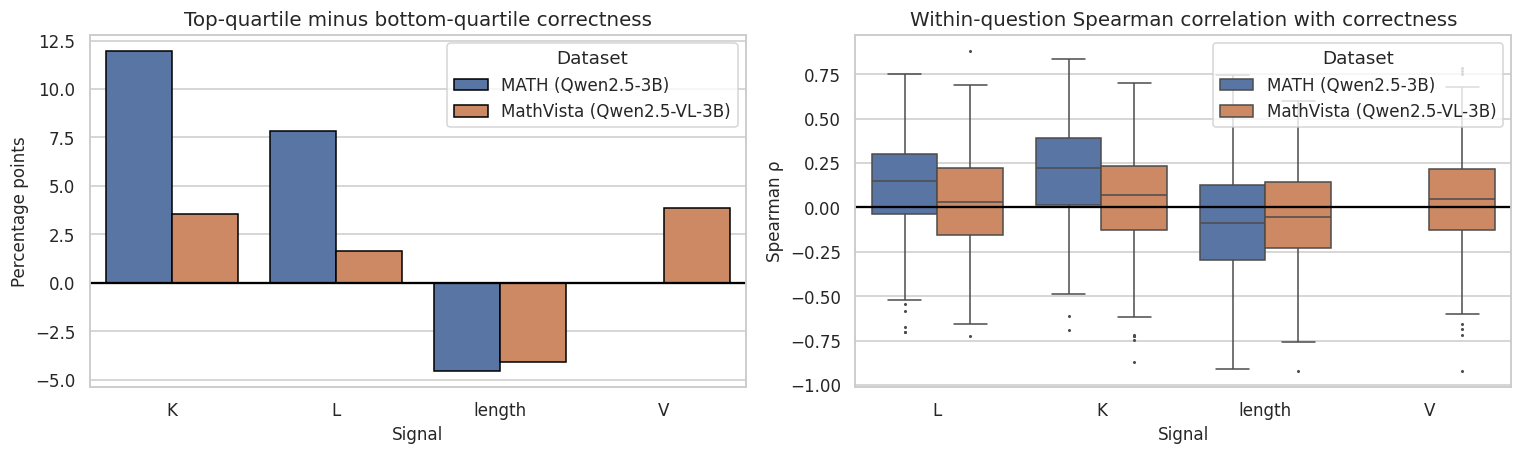

In [2]:
from task3_test_time_compute.src.fusion_ablation import quartile_correctness_gap, within_question_associations, shortest_rollout_accuracy, confidence_vision_correlations, token_trajectory
questions = {d: split_questions(d)[1] for d in DATASETS}

gaps = []
for dataset in DATASETS:
    for score in ["L", "K", "length"] + (["V"] if dataset == "mathvista" else []):
        gaps.append(quartile_correctness_gap(questions[dataset], score).assign(dataset=dataset))
gaps = pd.concat(gaps)
gaps.to_csv(f"{RESULTS_DIR}/quartile_gaps.csv", index=False)
summary = gaps.groupby(["dataset", "score"])[["top", "bottom", "gap"]].mean().mul(100).round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
plot = summary.reset_index()
plot["Dataset"] = plot["dataset"].map(DATASETS)
sns.barplot(data=plot, x="score", y="gap", hue="Dataset", ax=axes[0], edgecolor="black")
axes[0].axhline(0, color="black")
axes[0].set(title="Top-quartile minus bottom-quartile correctness", xlabel="Signal", ylabel="Percentage points")

associations = pd.concat([within_question_associations(questions[d]).assign(Dataset=DATASETS[d]) for d in DATASETS])
associations.to_csv(f"{RESULTS_DIR}/within_question_associations.csv", index=False)
sns.boxplot(data=associations.dropna(subset=["with_correct"]), x="signal", y="with_correct", hue="Dataset", ax=axes[1], fliersize=1)
axes[1].axhline(0, color="black")
axes[1].set(title="Within-question Spearman correlation with correctness", xlabel="Signal", ylabel="Spearman ρ")
save_figure("task3_3_signal_correctness")

## 3.1 Is each score just measuring length?
A strong correlation with length means a score may be selecting short responses rather than good ones. The shortest-rollout control measures what length alone achieves.

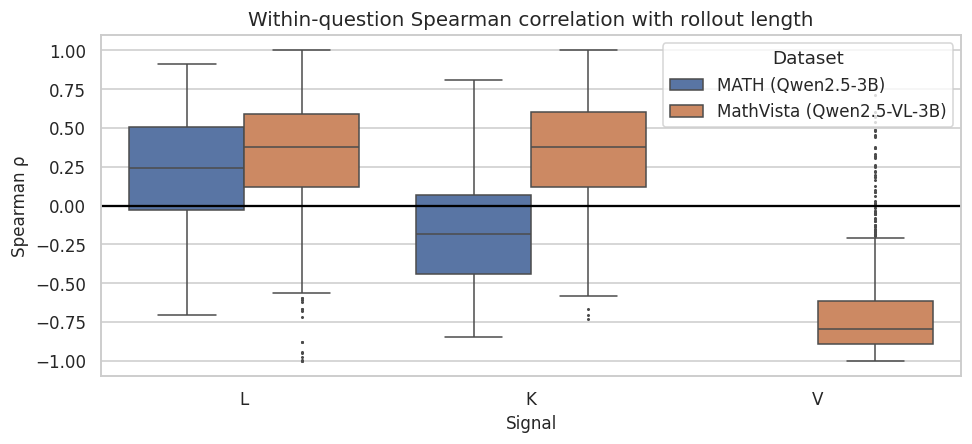

,Dataset,Shortest rollout (%),FirstAns at N=32 (%),Self-certainty at N=32 (%)
0,MATH (Qwen2.5-3B),62.50,64.40,70.62
1,MathVista (Qwen2.5-VL-3B),53.75,53.77,54.62


In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=associations[associations["signal"] != "length"].dropna(subset=["with_length"]), x="signal", y="with_length", hue="Dataset", ax=ax, fliersize=1)
ax.axhline(0, color="black")
ax.set(title="Within-question Spearman correlation with rollout length", xlabel="Signal", ylabel="Spearman ρ")
save_figure("task3_3_signal_length")

rows = [{"Dataset": DATASETS[d], "Shortest rollout (%)": 100 * shortest_rollout_accuracy(questions[d]),
         "FirstAns at N=32 (%)": pd.read_csv(f"{RESULTS_DIR}/method_table_{d}.csv", index_col=0).loc["first_ans", "32"],
         "Self-certainty at N=32 (%)": pd.read_csv(f"{RESULTS_DIR}/method_table_{d}.csv", index_col=0).loc["self_certainty", "32"]} for d in DATASETS]
controls = pd.DataFrame(rows).round(2)
controls.to_csv(f"{RESULTS_DIR}/length_control.csv", index=False)
display(controls)

## 3.2 Confidence and vision inside a rollout (MathVista)

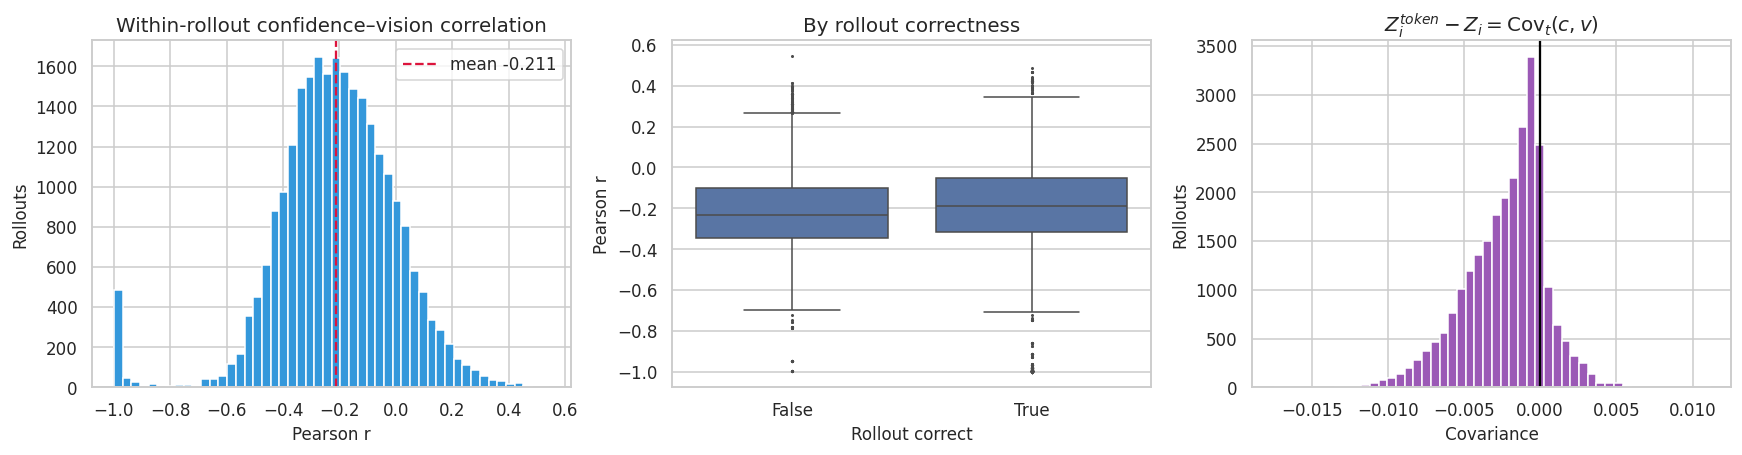

In [4]:
correlations = confidence_vision_correlations(questions["mathvista"])
correlations.to_csv(f"{RESULTS_DIR}/confidence_vision_correlations.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].hist(correlations["correlation"], bins=50, color="#3498db", edgecolor="white")
axes[0].axvline(correlations["correlation"].mean(), color="crimson", linestyle="--", label=f"mean {correlations['correlation'].mean():.3f}")
axes[0].set(title="Within-rollout confidence–vision correlation", xlabel="Pearson r", ylabel="Rollouts"); axes[0].legend()
sns.boxplot(data=correlations, x="correct", y="correlation", ax=axes[1], fliersize=1)
axes[1].set(title="By rollout correctness", xlabel="Rollout correct", ylabel="Pearson r")
axes[2].hist(correlations["covariance"], bins=50, color="#9b59b6", edgecolor="white")
axes[2].axvline(0, color="black")
axes[2].set(title=r"$Z^{token}_i - Z_i = \mathrm{Cov}_t(c,v)$", xlabel="Covariance", ylabel="Rollouts")
save_figure("task3_3_confidence_vision")

## 3.3 Tokenwise fusion against rollout-level VisConf
The ablation uses the same two aggregation rules, so any difference comes from where the signals are combined.

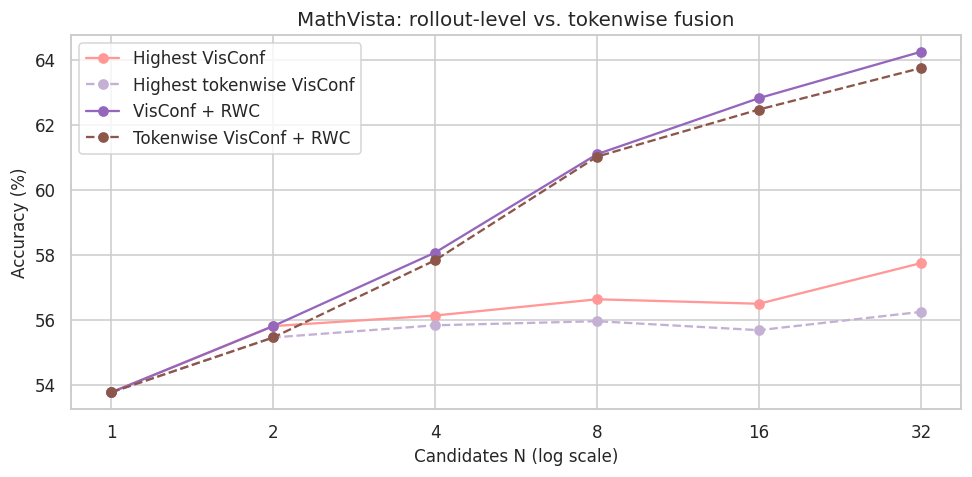

In [5]:
offline = pd.read_csv(f"{RESULTS_DIR}/offline_mathvista.csv")
keep = ["visconf", "visconf_token", "visconf_rwc", "visconf_token_rwc"]
summary = offline[offline["method"].isin(keep)].groupby(["N", "method"])["accuracy"].mean().mul(100).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
for method in keep:
    group = summary[summary["method"] == method]
    ax.plot(group["N"], group["accuracy"], marker="o", label=METHOD_LABELS[method], color=METHOD_COLORS[method], linestyle="--" if "token" in method else "-")
ax.set(title="MathVista: rollout-level vs. tokenwise fusion", xlabel="Candidates N (log scale)", ylabel="Accuracy (%)", xscale="log")
ax.set_xticks([1, 2, 4, 8, 16, 32]); ax.set_xticklabels([1, 2, 4, 8, 16, 32]); ax.legend()
save_figure("task3_3_tokenwise_fusion")

## 3.4 Illustrative trajectories
**Selection rule, fixed before viewing:** the first question in the held-out order with both correct and incorrect rollouts; within it, the longest correct and longest incorrect rollout. Bins average along the generation.

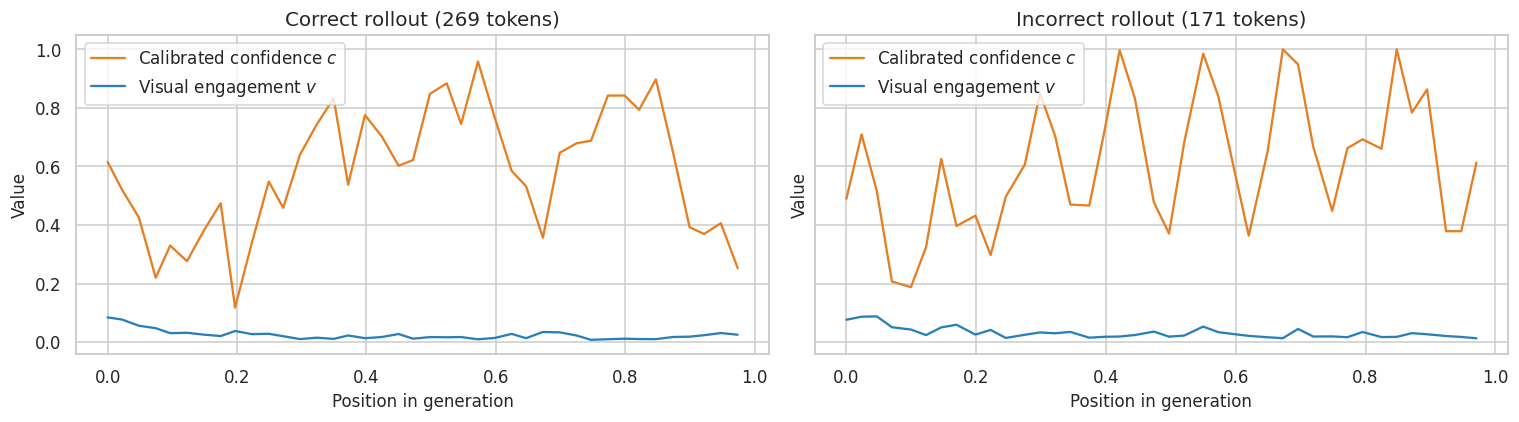

Question: 99 | correct rollouts: 26 of 32


In [6]:
q = next(q for q in questions["mathvista"] if 0 < q.correct.sum() < 32)
correct_id = max(np.flatnonzero(q.correct), key=lambda i: q.tokens[i])
wrong_id = max(np.flatnonzero(~q.correct), key=lambda i: q.tokens[i])
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, rollout, title in [(axes[0], correct_id, "Correct rollout"), (axes[1], wrong_id, "Incorrect rollout")]:
    t = token_trajectory(q, rollout)
    ax.plot(t["position"], t["confidence"], label="Calibrated confidence $c$", color="#e67e22")
    ax.plot(t["position"], t["engagement"], label="Visual engagement $v$", color="#2980b9")
    ax.set(title=f"{title} ({q.tokens[rollout]} tokens)", xlabel="Position in generation", ylabel="Value")
    ax.legend()
save_figure("task3_3_trajectories")
print("Question:", q.sample_id, "| correct rollouts:", q.correct.sum(), "of 32")